# LiH benchmark: EfficientSU2, UCCSD and fUCCSD with ZNE and CDR

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

## Setup

In [2]:
import contextlib
import io
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from pyscf import mcscf
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp
from slowquant.qiskit_interface.circuit_wavefunction import WaveFunctionCircuit
from slowquant.qiskit_interface.interface import QuantumInterface

from src.utils import load_config
from src.chem import get_molecule, get_problem, get_ansatz
from src.backend import run_vqe, get_transpiled
from src.mitigation import ZNE, CDR, M0

cfg = load_config("configs/lih.yaml")

molecule, mf, cas = get_molecule()
problem = get_problem()
e_nuc = molecule.energy_nuc()
mapper = JordanWignerMapper()

E_hf = mf.e_tot
E_fci = mcscf.CASCI(mf, cas[1], cas[0]).run().e_tot
print(f"HF  : {E_hf:.6f} Ha")
print(f"FCI : {E_fci:.6f} Ha")


Setting number of Numba threads to 1

HF  : -7.862024 Ha
FCI : -7.863219 Ha


## Ansatze

Each ansatz comes with its own Hamiltonian:

- **EfficientSU2, UCCSD** use the Qiskit Nature Hamiltonian.
- **fUCCSD** uses the Hamiltonian from SlowQuant's wavefunction, so it matches SlowQuant's orbitals.

UCCSD and fUCCSD start from θ = 0 (the HF state). EfficientSU2 starts from small random values, because θ = 0 is not the HF state for it.

In [3]:
ANSATZE = ["EfficientSU2", "UCCSD", "fUCCSD", "pp-tUPS"]
SEEDS = cfg["vqe"]["seeds"]
results = {name: {seed: {} for seed in SEEDS} for name in ANSATZE}

## VQE (noiseless) and transpiling

In [4]:
for name in ANSATZE:
    for seed in SEEDS:
        ansatz, hamiltonian, x0 = get_ansatz(name, seed)
        vqe_energy, theta_opt = run_vqe(ansatz, hamiltonian, x0)
        transpiled_ansatz, transpiled_hamiltonian = get_transpiled(ansatz, theta_opt, hamiltonian, seed)

        results[name][seed].update(ansatz=ansatz, hamiltonian=hamiltonian, theta_opt=theta_opt,
            transpiled_ansatz=transpiled_ansatz, transpiled_hamiltonian=transpiled_hamiltonian,
            E_exact=vqe_energy + e_nuc)
        print(f"{name:13s} seed={seed}  E_VQE = {vqe_energy + e_nuc:.6f}  "
              f"error vs FCI = {abs(vqe_energy + e_nuc - E_fci):.2e}  depth = {transpiled_ansatz.depth()}")

        print(f"seed : {seed}", len(results[name][seed]["theta_opt"]))

EfficientSU2  seed=37  E_VQE = -7.862021  error vs FCI = 1.20e-03  depth = 26
seed : 37 32
EfficientSU2  seed=42  E_VQE = -7.862018  error vs FCI = 1.20e-03  depth = 28
seed : 42 32
EfficientSU2  seed=99  E_VQE = -7.862020  error vs FCI = 1.20e-03  depth = 28
seed : 99 32
EfficientSU2  seed=200  E_VQE = -7.862024  error vs FCI = 1.20e-03  depth = 28
seed : 200 32


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


UCCSD         seed=37  E_VQE = -7.863219  error vs FCI = 5.95e-07  depth = 2187
seed : 37 26
UCCSD         seed=42  E_VQE = -7.863219  error vs FCI = 5.95e-07  depth = 2187
seed : 42 26
UCCSD         seed=99  E_VQE = -7.863219  error vs FCI = 5.95e-07  depth = 2187
seed : 99 26
UCCSD         seed=200  E_VQE = -7.863219  error vs FCI = 5.95e-07  depth = 2187
seed : 200 26
fUCCSD        seed=37  E_VQE = -7.863219  error vs FCI = 4.25e-07  depth = 817
seed : 37 26
fUCCSD        seed=42  E_VQE = -7.863219  error vs FCI = 4.25e-07  depth = 848
seed : 42 26
fUCCSD        seed=99  E_VQE = -7.863219  error vs FCI = 4.25e-07  depth = 827
seed : 99 26
fUCCSD        seed=200  E_VQE = -7.863219  error vs FCI = 4.25e-07  depth = 821
seed : 200 26
pp-tUPS       seed=37  E_VQE = -7.863162  error vs FCI = 5.71e-05  depth = 249
seed : 37 9
pp-tUPS       seed=42  E_VQE = -7.863162  error vs FCI = 5.71e-05  depth = 245
seed : 42 9
pp-tUPS       seed=99  E_VQE = -7.863162  error vs FCI = 5.71e-05  depth =

## ZNE

In [5]:
date = datetime.now().strftime("%Y-%m-%d")

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        zne = ZNE(seed)
        zne.run(r["transpiled_ansatz"], r["transpiled_hamiltonian"], e_nuc)
        zne.save(f"data/LiH_{name}_ZNE_seed{seed}_{date}.npz")
        r["zne"] = zne
        r["E_noisy"] = zne.energies[0]

EfficientSU2 | linear  mean R² = 0.999526
EfficientSU2 | poly    mean R² = 1.000000
EfficientSU2 | exp     mean R² = 0.999942
UCCSD | linear  mean R² = 0.948063
UCCSD | poly    mean R² = 1.000000
UCCSD | exp     mean R² = 0.994973
fUCCSD | linear  mean R² = 0.775780
fUCCSD | poly    mean R² = 1.000000
fUCCSD | exp     mean R² = 0.995619
pp-tUPS | linear  mean R² = 0.987838
pp-tUPS | poly    mean R² = 1.000000
pp-tUPS | exp     mean R² = 0.999948


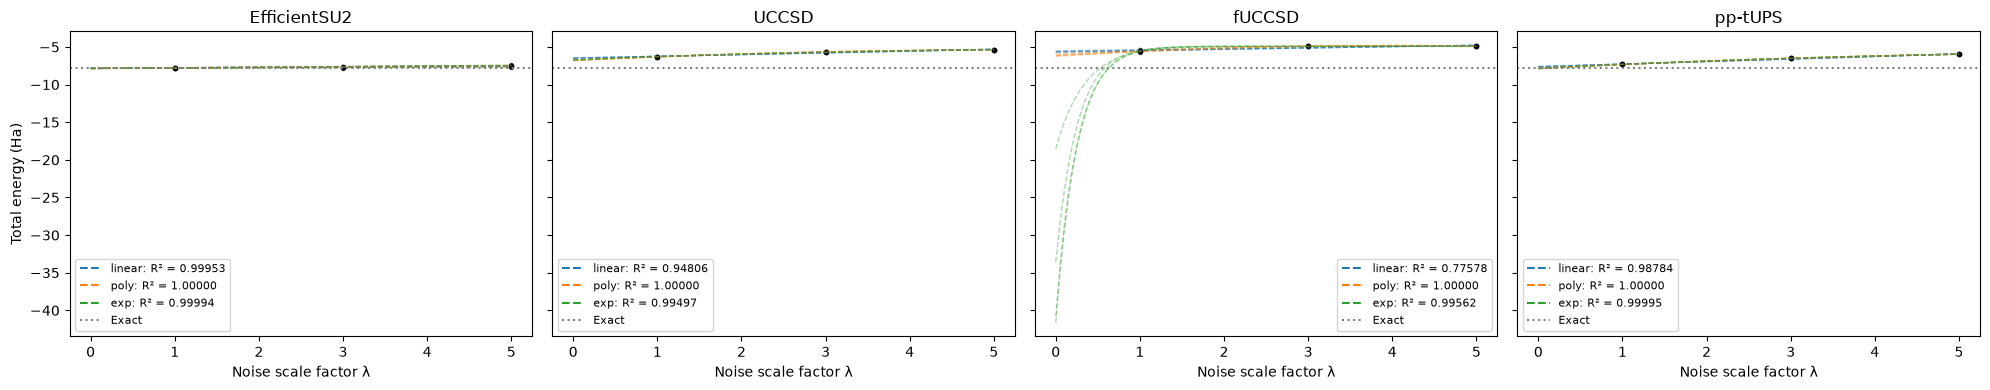

In [6]:
METHODS = ["linear", "poly", "exp"]
COLORS = {"linear": "tab:blue", "poly": "tab:orange", "exp": "tab:green"}
x = np.linspace(0, max(ZNE(SEEDS[0]).noise_factors), 100)

fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4), sharey=True)
for ax, name in zip(axes, ANSATZE):
    for seed in SEEDS:
        zne = results[name][seed]["zne"]
        ax.plot(zne.lambdas, zne.energies, "ko", ms=3, alpha=0.6)
        for m in METHODS:
            _, curve = zne.extrapolate(m)
            ax.plot(x, [curve(xi) for xi in x], "--", color=COLORS[m], alpha=0.4, lw=1)
    for m in METHODS:
        r2 = np.mean([results[name][s]["zne"].r_squared(m) for s in SEEDS])
        print(f"{name} | {m:6s}  mean R² = {r2:.6f}")
        ax.plot([], [], "--", color=COLORS[m], label=f"{m}: R² = {r2:.5f}")
    ax.axhline(np.mean([results[name][s]["E_exact"] for s in SEEDS]), color="gray", ls=":", label="Exact")
    ax.set_title(name); ax.set_xlabel("Noise scale factor λ"); ax.legend(fontsize=8)
axes[0].set_ylabel("Total energy (Ha)")
plt.tight_layout(); plt.show()


EfficientSU2 | linear  mean R² = 0.999526
EfficientSU2 | poly    mean R² = 1.000000
EfficientSU2 | exp     mean R² = 0.999942


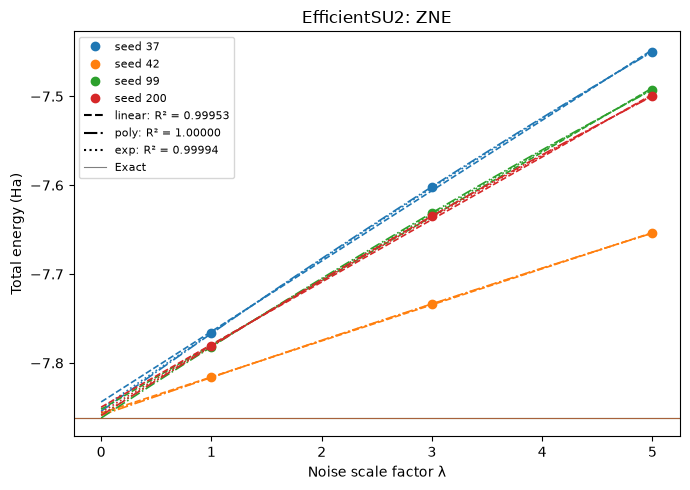

UCCSD | linear  mean R² = 0.948063
UCCSD | poly    mean R² = 1.000000
UCCSD | exp     mean R² = 0.994973


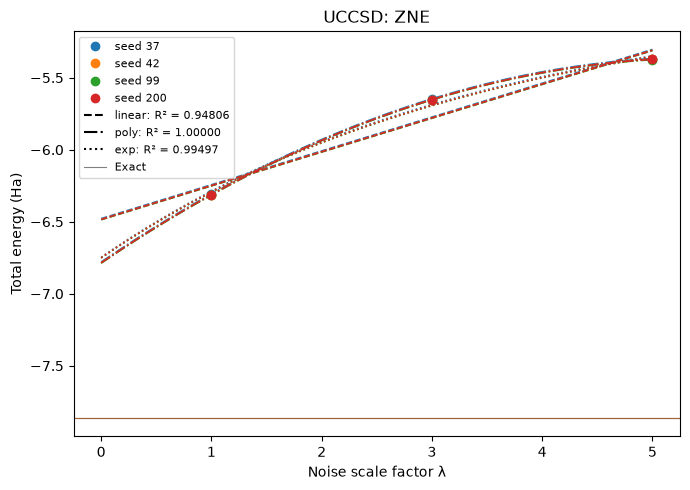

fUCCSD | linear  mean R² = 0.775780
fUCCSD | poly    mean R² = 1.000000
fUCCSD | exp     mean R² = 0.995619


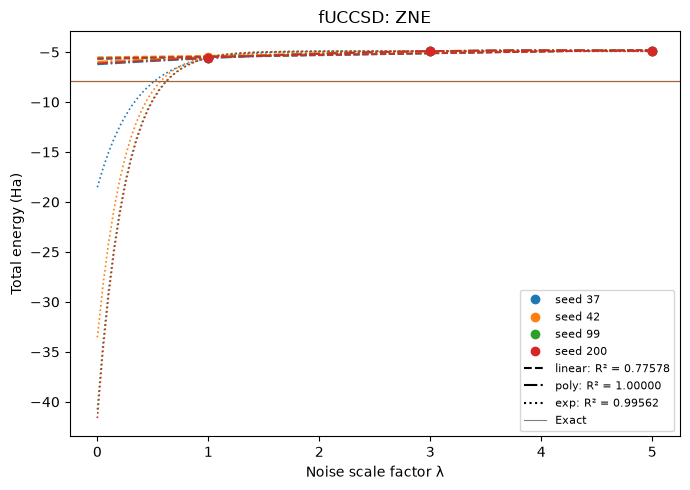

pp-tUPS | linear  mean R² = 0.987838
pp-tUPS | poly    mean R² = 1.000000
pp-tUPS | exp     mean R² = 0.999948


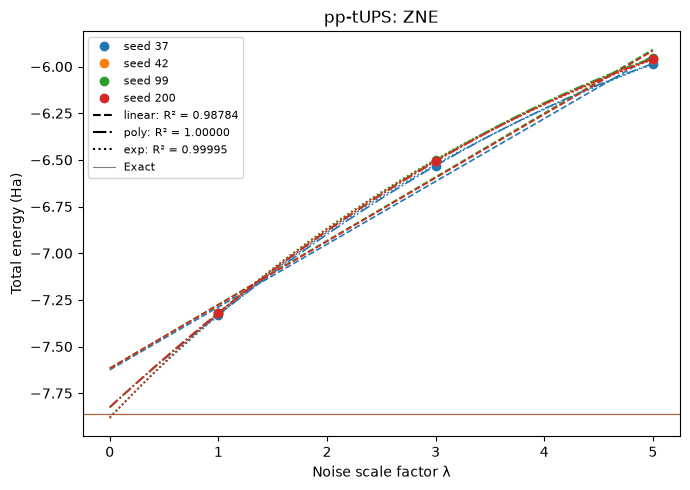

In [7]:
METHODS = ["linear", "poly", "exp"]
STYLES = {"linear": "--", "poly": "-.", "exp": ":"}
x = np.linspace(0, max(ZNE(SEEDS[0]).noise_factors), 100) 

for name in ANSATZE:
    fig, ax = plt.subplots(figsize=(7, 5))

    for i, seed in enumerate(SEEDS):
        zne = results[name][seed]["zne"]
        c = f"C{i}"
        ax.plot(zne.lambdas, zne.energies, "o", color=c, label=f"seed {seed}")
        for m in METHODS:
            _, curve = zne.extrapolate(m)
            ax.plot(x, [curve(xi) for xi in x], STYLES[m], color=c, lw=1.2)
        ax.axhline(results[name][seed]["E_exact"], color=c, lw=0.8, alpha=0.5)

    # legend entries for the line styles, with the mean R² over seeds
    for m in METHODS:
        r2 = np.mean([results[name][s]["zne"].r_squared(m) for s in SEEDS])
        print(f"{name} | {m:6s}  mean R² = {r2:.6f}")
        ax.plot([], [], STYLES[m], color="k", label=f"{m}: R² = {r2:.5f}")
    ax.plot([], [], "-", color="k", lw=0.8, alpha=0.5, label="Exact")

    ax.set_title(f"{name}: ZNE")
    ax.set_xlabel("Noise scale factor λ")
    ax.set_ylabel("Total energy (Ha)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


In [8]:
METHODS = ["linear", "poly", "exp"]

def distance_to_one(r2):
    return np.inf if np.isnan(r2) else abs(1 - r2)       # a NaN R² is never picked

print(f"{'Ansatz':13s} {'seed':>5s} " + " ".join(f"{m:>10s}" for m in METHODS) + "   best     ZNE error (Ha)")
for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        r2 = {m: r["zne"].r_squared(m) for m in METHODS}
        best = min(METHODS, key=lambda m: distance_to_one(r2[m]))     # R² closest to 1

        r["zne_method"] = best
        r["E_zne"], _ = r["zne"].extrapolate(best)
        print(f"{name:13s} {seed:5d} " + " ".join(f"{r2[m]:10.6f}" for m in METHODS)
              + f"   {best:6s}   {abs(r['E_zne'] - r['E_exact']):.2e}")



Ansatz         seed     linear       poly        exp   best     ZNE error (Ha)
EfficientSU2     37   0.999421   1.000000   0.999950   poly     7.72e-03
EfficientSU2     42   0.999874   1.000000   0.999992   poly     3.15e-03
EfficientSU2     99   0.999396   1.000000   0.999915   poly     1.23e-04
EfficientSU2    200   0.999411   1.000000   0.999913   poly     2.95e-03
UCCSD            37   0.948063   1.000000   0.995109   poly     1.08e+00
UCCSD            42   0.948063   1.000000   0.994947   poly     1.08e+00
UCCSD            99   0.948063   1.000000   0.994886   poly     1.08e+00
UCCSD           200   0.948063   1.000000   0.994950   poly     1.08e+00
fUCCSD           37   0.787783   1.000000   0.996386   poly     1.62e+00
fUCCSD           42   0.761193   1.000000   0.991996   poly     1.91e+00
fUCCSD           99   0.773588   1.000000   0.997019   poly     1.73e+00
fUCCSD          200   0.780556   1.000000   0.997073   poly     1.72e+00
pp-tUPS          37   0.988445   1.000000   0

Choose the extrapolation for each ansatz from the plots:

In [9]:
METHODS = ["linear", "poly", "exp"]
zne_method = {name: {} for name in ANSATZE}       # zne_method[name][seed], filled at run time

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        r2 = {m: r["zne"].r_squared(m) for m in METHODS}
        method = min(METHODS, key=lambda m: np.inf if np.isnan(r2[m]) else abs(1 - r2[m]))

        zne_method[name][seed] = method
        r["E_zne"], _ = r["zne"].extrapolate(method)
        print(f"{name:13s} ({method:6s}) Seed = {seed}  Noisy error = {abs(r['E_noisy'] - r['E_exact']):.6f}   "
              f"ZNE error = {abs(r['E_zne'] - r['E_exact']):.6f} Ha   "
              f"R² = " + " ".join(f"{m}:{r2[m]:.5f}" for m in METHODS))


EfficientSU2  (poly  ) Seed = 37  Noisy error = 0.095218   ZNE error = 0.007717 Ha   R² = linear:0.99942 poly:1.00000 exp:0.99995
EfficientSU2  (poly  ) Seed = 42  Noisy error = 0.045718   ZNE error = 0.003151 Ha   R² = linear:0.99987 poly:1.00000 exp:0.99999
EfficientSU2  (poly  ) Seed = 99  Noisy error = 0.080137   ZNE error = 0.000123 Ha   R² = linear:0.99940 poly:1.00000 exp:0.99991
EfficientSU2  (poly  ) Seed = 200  Noisy error = 0.080706   ZNE error = 0.002945 Ha   R² = linear:0.99941 poly:1.00000 exp:0.99991
UCCSD         (poly  ) Seed = 37  Noisy error = 1.556539   ZNE error = 1.083535 Ha   R² = linear:0.94806 poly:1.00000 exp:0.99511
UCCSD         (poly  ) Seed = 42  Noisy error = 1.550587   ZNE error = 1.077583 Ha   R² = linear:0.94806 poly:1.00000 exp:0.99495
UCCSD         (poly  ) Seed = 99  Noisy error = 1.548364   ZNE error = 1.075361 Ha   R² = linear:0.94806 poly:1.00000 exp:0.99489
UCCSD         (poly  ) Seed = 200  Noisy error = 1.550682   ZNE error = 1.077678 Ha   R² 

## CDR

In [10]:
for name in ANSATZE:
    for seed in SEEDS:
        print(f"{name}\n")
        r = results[name][seed]
        cdr = CDR(seed)
        circuits = cdr.training_circuits(r["transpiled_ansatz"])
        cdr.training_data(circuits, r["hamiltonian"], e_nuc)      # LiH: keep transpiled=True
        cdr.save(f"data/LiH_{name}_CDR_seed{seed}_{date}.npz")
        r["cdr"] = cdr

EfficientSU2

Seed = 37 n = 34 non-Clifford gates, k = 1 -> C(n, k) = 34
EfficientSU2

Seed = 42 n = 39 non-Clifford gates, k = 1 -> C(n, k) = 39
EfficientSU2

Seed = 99 n = 38 non-Clifford gates, k = 1 -> C(n, k) = 38
EfficientSU2

Seed = 200 n = 38 non-Clifford gates, k = 1 -> C(n, k) = 38
UCCSD

Seed = 37 n = 226 non-Clifford gates, k = 1 -> C(n, k) = 226
UCCSD

Seed = 42 n = 226 non-Clifford gates, k = 1 -> C(n, k) = 226
UCCSD

Seed = 99 n = 226 non-Clifford gates, k = 1 -> C(n, k) = 226
UCCSD

Seed = 200 n = 226 non-Clifford gates, k = 1 -> C(n, k) = 226
fUCCSD

Seed = 37 n = 129 non-Clifford gates, k = 1 -> C(n, k) = 129
fUCCSD

Seed = 42 n = 136 non-Clifford gates, k = 1 -> C(n, k) = 136
fUCCSD

Seed = 99 n = 132 non-Clifford gates, k = 1 -> C(n, k) = 132
fUCCSD

Seed = 200 n = 137 non-Clifford gates, k = 1 -> C(n, k) = 137
pp-tUPS

Seed = 37 n = 48 non-Clifford gates, k = 1 -> C(n, k) = 48
pp-tUPS

Seed = 42 n = 44 non-Clifford gates, k = 1 -> C(n, k) = 44
pp-tUPS

Seed = 99 n 

To skip the slow part later, load saved training data instead:

```python
cdr = CDR(42)
cdr.load("data/LiH_fUCCSD_CDR_seed42_<date>.npz")
results["fUCCSD"][42]["cdr"] = cdr
```

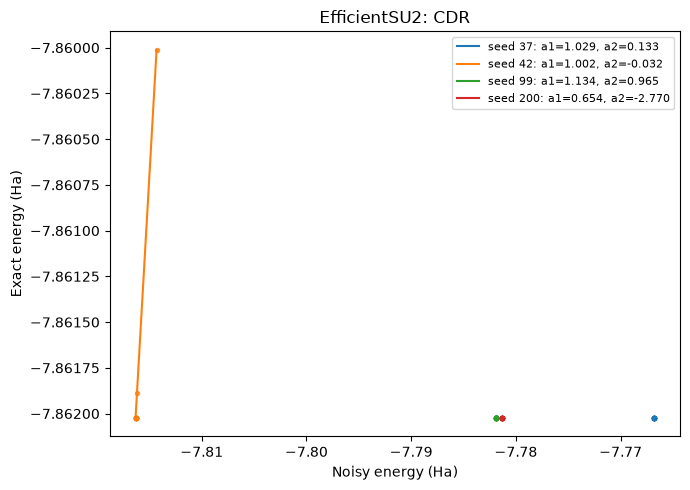

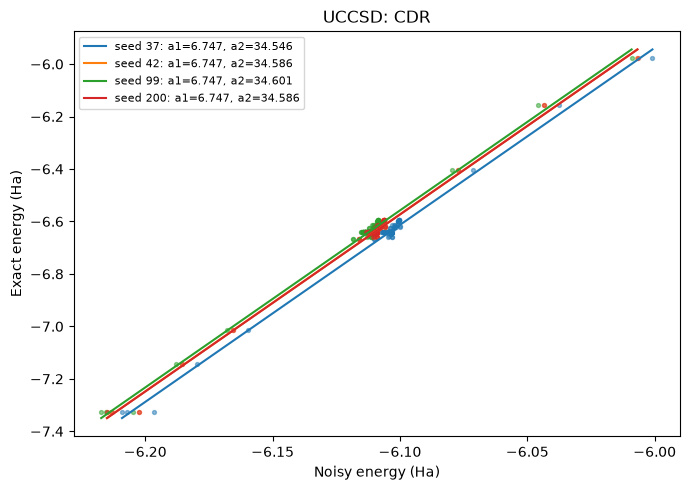

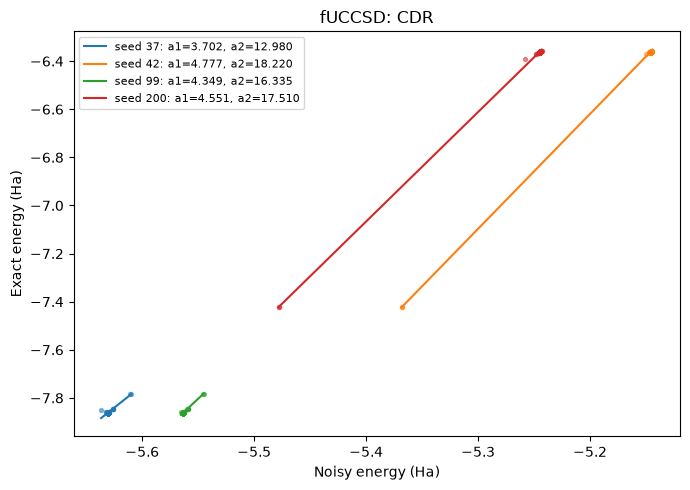

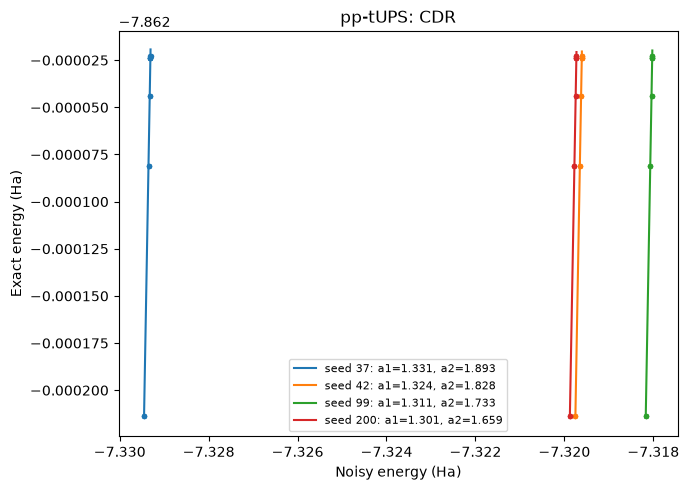

In [11]:
for name in ANSATZE:
    fig, ax = plt.subplots(figsize=(7, 5))

    for i, seed in enumerate(SEEDS):
        r = results[name][seed]; cdr = r["cdr"]
        a1, a2 = cdr.fit()
        r["E_cdr"] = float(cdr.mitigate(r["E_noisy"]))
        x = np.linspace(cdr.X_noisy.min(), cdr.X_noisy.max(), 100)
        ax.scatter(cdr.X_noisy, cdr.X_exact, s=8, color=f"C{i}", alpha=0.5)
        ax.plot(x, cdr.mitigate(x), "-", color=f"C{i}", label=f"seed {seed}: a1={a1:.3f}, a2={a2:.3f}")

    ax.set_title(f"{name}: CDR")
    ax.set_xlabel("Noisy energy (Ha)")
    ax.set_ylabel("Exact energy (Ha)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"plots/LiH_CDR_{name}_{date}.png", dpi=200)
    plt.show()


## M0

In [12]:
M0_ANSATZE = ["fUCCSD", "pp-tUPS"]   # M0 only works with SlowQuant ansatze

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        if name in M0_ANSATZE:
            r["E_noisy_m0"], r["E_m0"] = M0(seed).run(name, r["theta_opt"])
            print(f"{name:13s} Seed = {seed}  Noisy (sampler) error = {abs(r['E_noisy_m0'] - r['E_exact']):.6f}   "
                  f"M0 error = {abs(r['E_m0'] - r['E_exact']):.6f} Ha")
        else:
            r["E_noisy_m0"] = r["E_m0"] = np.nan


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


fUCCSD        Seed = 37  Noisy (sampler) error = 2.284673   M0 error = 0.050608 Ha


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


fUCCSD        Seed = 42  Noisy (sampler) error = 2.366746   M0 error = 0.116123 Ha


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


...

/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


pp-tUPS       Seed = 42  Noisy (sampler) error = 0.777897   M0 error = 0.008342 Ha


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


pp-tUPS       Seed = 99  Noisy (sampler) error = 0.524959   M0 error = 0.010811 Ha
pp-tUPS       Seed = 200  Noisy (sampler) error = 0.503785   M0 error = 0.015846 Ha


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: divide by zero encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: overflow encountered in matmul
  C_new = M @ C
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/SlowQuant/slowquant/qiskit_interface/util.py:610: RuntimeWarning: invalid value encountered in matmul
  C_new = M @ C


## Summary

In [13]:
def errs(name, key):
    return np.array([abs(results[name][s][key] - results[name][s]["E_exact"]) for s in SEEDS])

keys = ("E_noisy", "E_zne", "E_cdr", "E_m0")

print(f"{'Ansatz':13s} {'err Noisy':>22s} {'err ZNE':>22s} {'err CDR':>22s} {'err M0':>22s}")
for name in ANSATZE:
    cells = []
    for k in keys:
        e = errs(name, k)
        cells.append(f"{'-':>22s}" if np.isnan(e).all() else f"{e.mean():10.2e} ± {e.std():8.2e}")
    print(f"{name:13s} " + " ".join(cells))


Ansatz                     err Noisy                err ZNE                err CDR                 err M0
EfficientSU2    7.54e-02 ± 1.82e-02   3.48e-03 ± 2.72e-03   2.84e-06 ± 4.64e-06                      -
UCCSD           1.55e+00 ± 3.03e-03   1.08e+00 ± 3.03e-03   1.45e-01 ± 1.23e-14                      -
fUCCSD          2.31e+00 ± 6.15e-02   1.75e+00 ± 1.02e-01   2.09e-03 ± 1.25e-03   6.34e-02 ± 4.21e-02
pp-tUPS         5.41e-01 ± 4.46e-03   3.77e-02 ± 1.03e-03   1.69e-04 ± 6.59e-06   9.63e-03 ± 4.45e-03


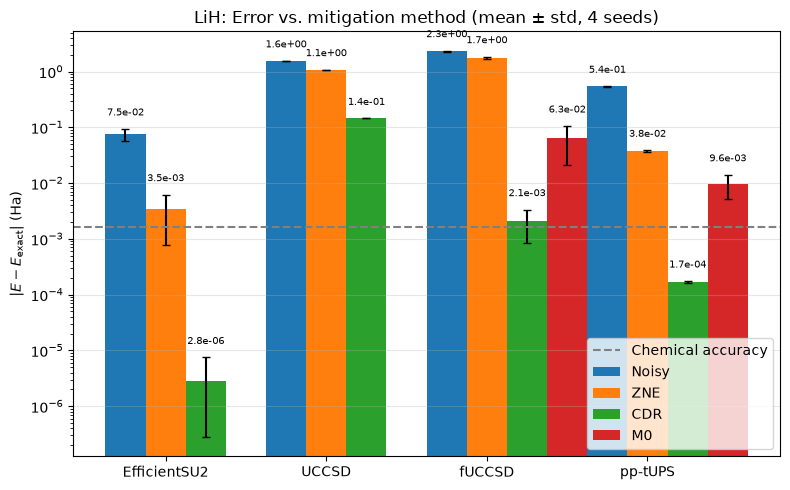

In [14]:
import numpy as np
import matplotlib.pyplot as plt

methods = [("E_noisy", "Noisy"), ("E_zne", "ZNE"), ("E_cdr", "CDR"), ("E_m0", "M0")]
w = 0.25
x = np.arange(len(ANSATZE))

def errs(name, key):
    """|E - E_exact| for every seed of one ansatz."""
    return np.array([abs(results[name][s][key] - results[name][s]["E_exact"]) for s in SEEDS])

fig, ax = plt.subplots(figsize=(8, 5))
for i, (key, label) in enumerate(methods):
    mean = np.array([errs(n, key).mean() for n in ANSATZE])
    std = np.array([errs(n, key).std() for n in ANSATZE])
    lower = np.minimum(std, 0.9 * mean)          # keeps the lower error bar positive on the log axis
    bars = ax.bar(x + (i - 1) * w, mean, w, yerr=[lower, std], capsize=3, label=label)
    ax.bar_label(bars, labels=[f"{m:.1e}" for m in mean], fontsize=7, padding=8)

plt.axhline(1.6e-3, color="gray", ls="--", label="Chemical accuracy")

ax.set_xticks(x)
ax.set_xticklabels(ANSATZE)
ax.set_ylabel(r"$|E - E_\mathrm{exact}|$ (Ha)")
ax.set_yscale("log")
ax.set_title(f"LiH: Error vs. mitigation method (mean ± std, {len(SEEDS)} seeds)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"plots/LiH_mitigation_errors_{date}.png", dpi=200)
plt.show()
